In [3]:
import os
from prepare_data import process_all_folds

# Using the Fold 5 training file as a sentinel to check if the data preparation has already run
file_sentinel = "data/MSLR-WEB10K/Fold5/train_clean.txt"

if not os.path.exists(file_sentinel):
    print("Clean data not found. Starting extraction from raw SVM-Rank files...")
    process_all_folds(base_dataset_dir="data/MSLR-WEB10K", num_folds=5)
else:
    print("Data already formatted and ready for training. Data preparation step skipped.")

Data already formatted and ready for training. Data preparation step skipped.


In [4]:
import json
import os
import multiprocessing as mp
from utils import run_experiment

RESULTS_FILE = "final_results.json"

# 1. Controlla se i risultati sono già stati salvati
if os.path.exists(RESULTS_FILE):
    print(f"File '{RESULTS_FILE}' trovato! Caricamento dei risultati...")
    with open(RESULTS_FILE, "r") as f:
        final_results = json.load(f)
    print("Risultati caricati con successo da disco. Addestramento saltato.\n")

else:
    print("Nessun salvataggio trovato. Avvio dell'addestramento degli esperimenti...\n")
    
    experiments = [
        {"name": "Baseline (GBDT no EFB)", "use_goss": False, "use_efb": False},
        {"name": "Solo EFB", "use_goss": False, "use_efb": True},
        {"name": "Solo GOSS", "use_goss": True, "use_efb": False},
        {"name": "LightGBM (GOSS + EFB)", "use_goss": True, "use_efb": True},
    ]

    context = mp.get_context('spawn')
    manager = context.Manager()
    results_dict = manager.dict()

    for conf in experiments:
        p = context.Process(
            target=run_experiment, 
            args=(conf["name"], conf["use_goss"], conf["use_efb"], results_dict)
        )
        
        p.start() 
        p.join()  
        
        if p.exitcode != 0:
            print(f"Attenzione: L'esperimento '{conf['name']}' è fallito con codice OS {p.exitcode}.")
        else:
            print(f"--- Processo per '{conf['name']}' chiuso con successo. ---\n")

    # Converti il dizionario gestito dal Manager in un dict Python standard
    final_results = dict(results_dict)
    
    # 2. Salva i risultati su file JSON
    with open(RESULTS_FILE, "w") as f:
        json.dump(final_results, f, indent=4)
        
    print(f"\nTraining completato. Risultati salvati in '{RESULTS_FILE}'.")

Nessun salvataggio trovato. Avvio dell'addestramento degli esperimenti...


Start experiment: Baseline (GBDT no EFB)
[LightGBM] [Info] Calculating query boundaries...
[LightGBM] [Info] Construct bin mappers from text data time 0.92 seconds
[200]	valid's ndcg@1: 0.493824	valid's ndcg@3: 0.483009	valid's ndcg@5: 0.488243	valid's ndcg@10: 0.507159	test's ndcg@1: 0.488681	test's ndcg@3: 0.480484	test's ndcg@5: 0.487904	test's ndcg@10: 0.504761
[400]	valid's ndcg@1: 0.497524	valid's ndcg@3: 0.483577	valid's ndcg@5: 0.489917	valid's ndcg@10: 0.508278	test's ndcg@1: 0.486748	test's ndcg@3: 0.484474	test's ndcg@5: 0.490159	test's ndcg@10: 0.507503
[600]	valid's ndcg@1: 0.496614	valid's ndcg@3: 0.482496	valid's ndcg@5: 0.491357	valid's ndcg@10: 0.508433	test's ndcg@1: 0.490695	test's ndcg@3: 0.48394	test's ndcg@5: 0.487326	test's ndcg@10: 0.506638
[800]	valid's ndcg@1: 0.494743	valid's ndcg@3: 0.48197	valid's ndcg@5: 0.489506	valid's ndcg@10: 0.507438	test's ndcg@1: 0.485081	test's ndcg@3: 0.48

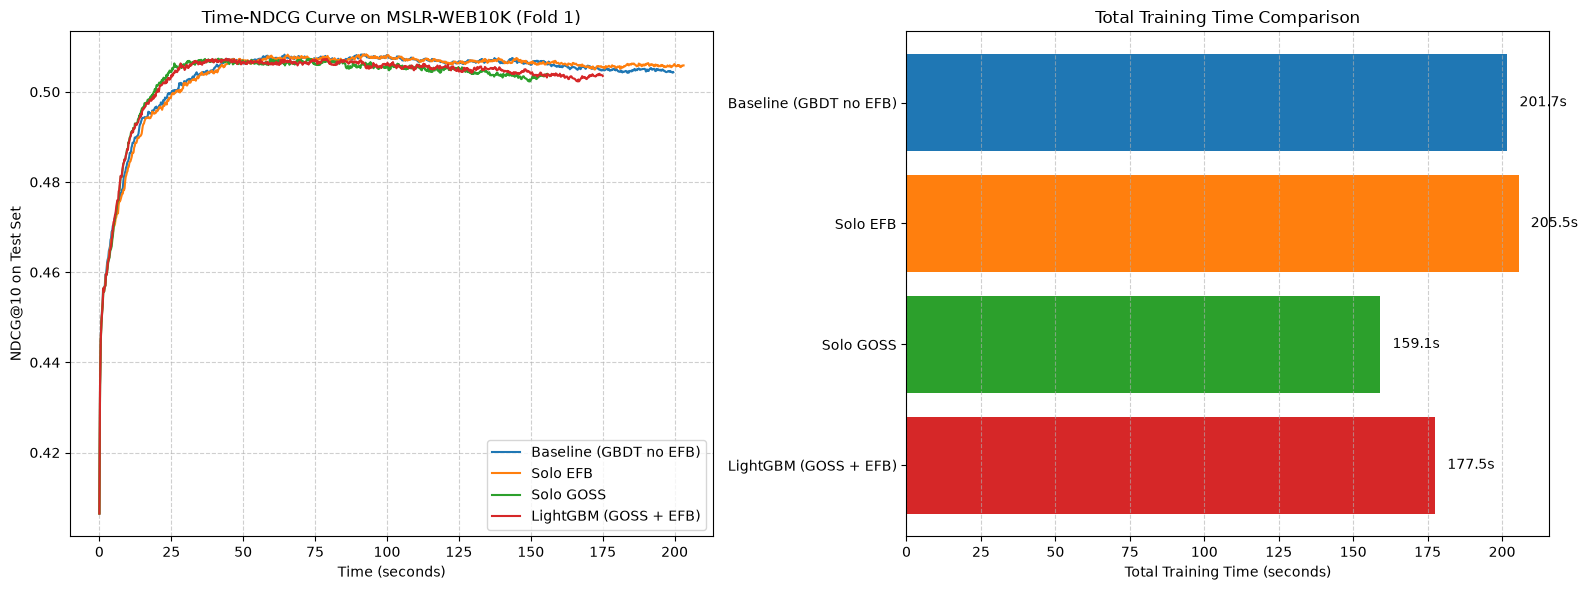

In [5]:
import matplotlib.pyplot as plt
import numpy as np

experiment_names = list(final_results.keys())
times = [final_results[name]["time"] for name in experiment_names]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# GRAPH 1: Time-NDCG Curve (Come nel paper originale)
for name in experiment_names:
    ndcg_history = final_results[name]["ndcg_history"]
    time_history = final_results[name]["time_history"]
    
    # Asse X: Tempo cumulativo in secondi, Asse Y: NDCG@10
    ax1.plot(time_history, ndcg_history, label=name, linewidth=1.5)

ax1.set_title("Time-NDCG Curve on MSLR-WEB10K (Fold 1)")
ax1.set_xlabel("Time (seconds)")
ax1.set_ylabel("NDCG@10 on Test Set")
ax1.legend(loc="lower right")
ax1.grid(True, linestyle='--', alpha=0.6)


# GRAPH 2: Training Time Comparison 
y_pos = np.arange(len(experiment_names))
bars = ax2.barh(y_pos, times, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
ax2.set_yticks(y_pos)
ax2.set_yticklabels(experiment_names)
ax2.invert_yaxis()
ax2.set_xlabel("Total Training Time (seconds)")
ax2.set_title("Total Training Time Comparison")
ax2.grid(True, axis='x', linestyle='--', alpha=0.6)

for bar in bars:
    width = bar.get_width()
    ax2.text(width + max(times)*0.02, bar.get_y() + bar.get_height()/2, 
             f'{width:.1f}s', ha='left', va='center')

plt.tight_layout()
plt.show()

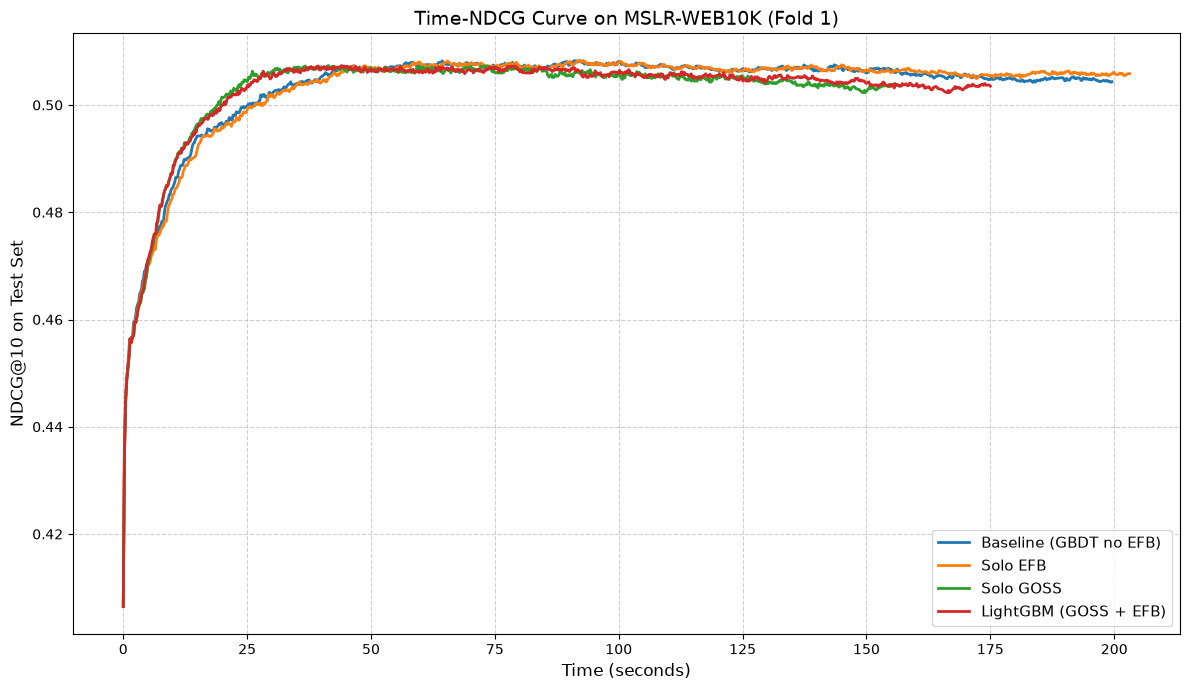

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Estrazione dati (assumendo che final_results sia già definito)
experiment_names = list(final_results.keys())

plt.figure(figsize=(12, 7))

# GRAPH 1: Time-NDCG Curve (Come nel paper originale)
for name in experiment_names:
    ndcg_history = final_results[name]["ndcg_history"]
    time_history = final_results[name]["time_history"]
    
    # Asse X: Tempo cumulativo in secondi, Asse Y: NDCG@10
    plt.plot(time_history, ndcg_history, label=name, linewidth=2.0)

plt.title("Time-NDCG Curve on MSLR-WEB10K (Fold 1)", fontsize=14)
plt.xlabel("Time (seconds)", fontsize=12)
plt.ylabel("NDCG@10 on Test Set", fontsize=12)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


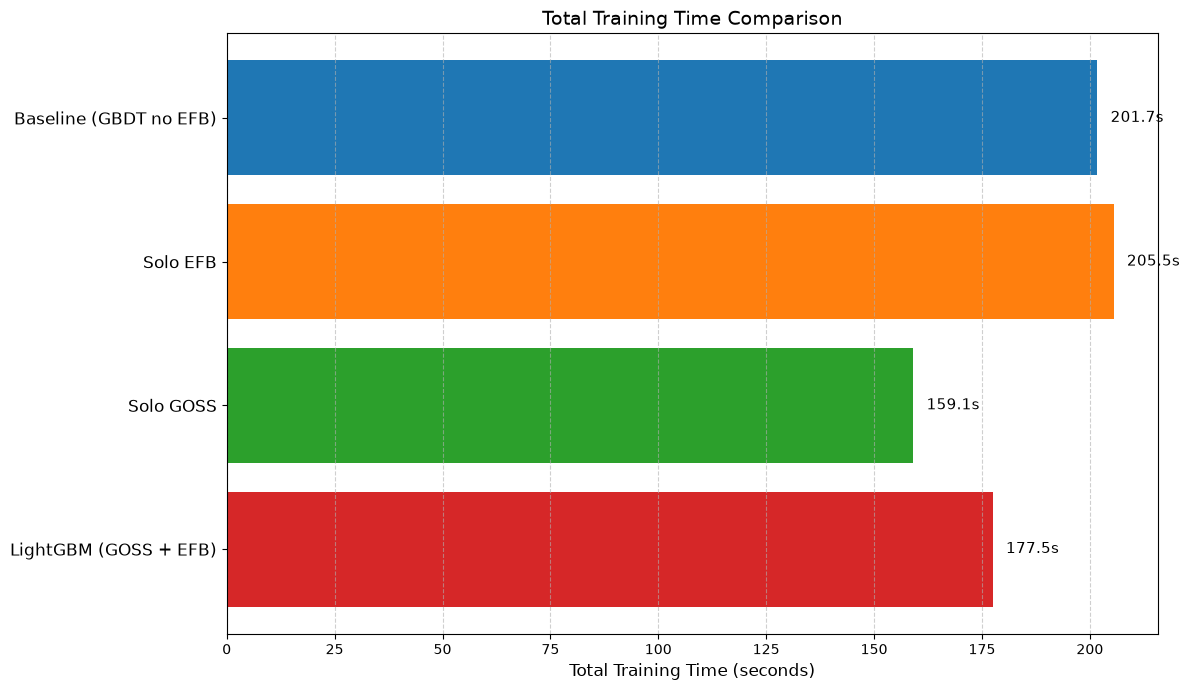

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Estrazione dati (nel caso vengano eseguiti in modo indipendente)
experiment_names = list(final_results.keys())
times = [final_results[name]["time"] for name in experiment_names]

plt.figure(figsize=(12, 7))

# GRAPH 2: Training Time Comparison 
y_pos = np.arange(len(experiment_names))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# Assicuriamoci che ci siano abbastanza colori se gli esperimenti sono più di 4
if len(experiment_names) > len(colors):
    colors = plt.cm.tab10(np.linspace(0, 1, len(experiment_names)))

bars = plt.barh(y_pos, times, color=colors)
plt.yticks(y_pos, experiment_names, fontsize=12)
plt.gca().invert_yaxis() # capovolge l'asse y per avere il primo in alto
plt.xlabel("Total Training Time (seconds)", fontsize=12)
plt.title("Total Training Time Comparison", fontsize=14)
plt.grid(True, axis='x', linestyle='--', alpha=0.6)

# Aggiunta delle etichette di testo alla fine di ogni barra
for bar in bars:
    width = bar.get_width()
    plt.text(width + max(times)*0.015, bar.get_y() + bar.get_height()/2, 
             f'{width:.1f}s', ha='left', va='center', fontsize=11)

plt.tight_layout()
plt.show()